In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

In [4]:
prefix = '/mnt/staging/' # or 
mouse='cm229'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"

h5_root = step_3_root+mouse+'/dlc_h5s/'
video_root = step_3_root+mouse+'/dlc_movies/'
mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'
figure_config_root = str(PREPARES / "config") + "/"


fetch_path_rest = str(PREPARES / "epochs-rest") + "/"

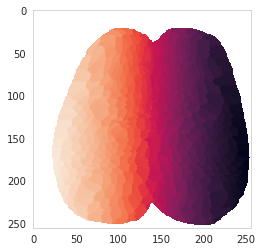

In [5]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [6]:
sensory_ind = load_pickle(fetch_path_S1+'brightest_ind_'+mouse)
M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse)
M1_ind = load_pickle(fetch_path_M1+'M1_ind_'+mouse)

# load resting data

In [7]:
all_gathered = ['M_jrgeco','M_gcamp','M_chbt',
               'M_day_label','M_LFP_vel','M_RFP_vel','M_ind_stop',
                'M_ind','M_rotf','M_is_groom','M_rotf_smooth',
               'M_body_pc','M_face_pc','M_body_pc_smooth',
               'M_mirrorLFP_vel','M_mirrorLFP_vel_norm',
               'M_mirrorRFP_vel','M_mirrorRFP_vel_norm',
               'M_mirrorLHP_vel','M_mirrorLHP_vel_norm',
               'M_mirrorRHP_vel','M_mirrorRHP_vel_norm']

f = scipy.io.loadmat(fetch_path_rest+'final_'+mouse+'_raw.mat'
                       )

for key in all_gathered:
    exec("{} = np.squeeze(f['{}'])".format(key,key))


    

Text(0.5, 1.0, 'M_face_pc')

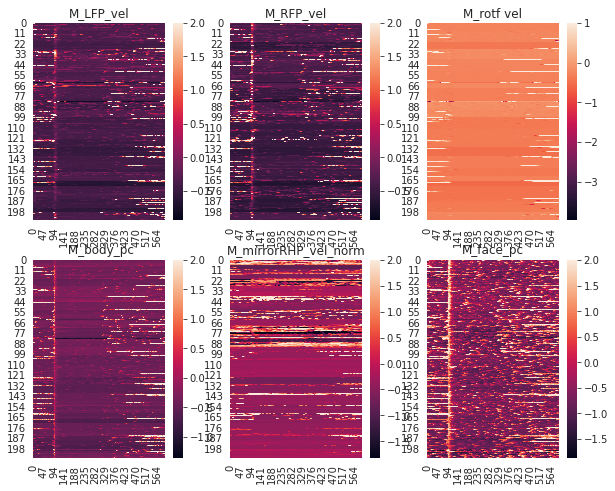

In [8]:


plt.figure(figsize=(10,8))
t_range=range(0,600)
plt.subplot(231)
sns.heatmap(M_LFP_vel[t_range,:].T,vmax=2)
plt.title('M_LFP_vel')
plt.subplot(232)
sns.heatmap(M_RFP_vel[t_range,:].T,vmax=2)
plt.title('M_RFP_vel')
plt.subplot(233)
sns.heatmap(M_rotf[t_range,:].T,vmax=1)
plt.title('M_rotf vel')
plt.subplot(234)
sns.heatmap(M_body_pc[t_range,:].T,vmax=2)
plt.title(' M_body_pc')
plt.subplot(235)
sns.heatmap(M_mirrorRHP_vel_norm[t_range,:].T,vmax=2)
plt.title('M_mirrorRHP_vel_norm')
plt.subplot(236)
sns.heatmap(M_face_pc[t_range,:].T,vmax=2)
plt.title('M_face_pc')

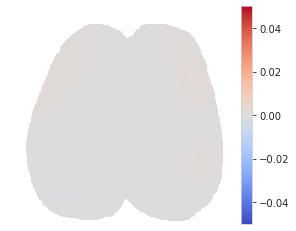

In [11]:
T_PRE_new=80
T = M_body_pc.shape[0]
sns.set_style("whitegrid", {'axes.grid' : False})
t_ax = np.divide(range(-T_PRE_new,T-T_PRE_new),20)
win3 = np.logical_and(t_ax>-10,t_ax<-1)
Y3_map = np.mean(np.mean(M_jrgeco[:,win3,:],axis=1),axis=-1)
show_map(Y3_map,[-0.05,0.05],cmap='coolwarm',IDX_sorted=IDX_sorted)


In [12]:
num_bouts = M_rotf.shape[1]
# stopind = np.zeros(num_bouts)
# for i in range(num_bouts):
#     try:
#         stopind[i] = np.argmax(np.where(M_body_pc_smooth[running_onset:,i]<0.2))
#     except:
#         continue
# oo = np.argsort(stopind)
ss_ind = np.argsort(M_ind_stop-M_ind)

<AxesSubplot:>

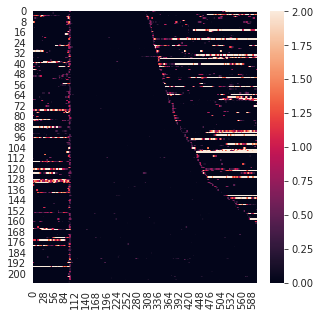

In [13]:
plt.figure(figsize=(5,5))
sns.heatmap(M_body_pc[:,ss_ind].transpose(),vmin=-0,vmax=2)



In [14]:
M_jrgeco = M_jrgeco[:,:,ss_ind]
M_gcamp = M_gcamp[:,:,ss_ind]
M_chbt = M_chbt[:,:,ss_ind]
M_day_label = M_day_label[ss_ind]
M_ind = M_ind[ss_ind]
M_ind_stop = M_ind_stop[ss_ind]
M_LFP_vel=M_LFP_vel[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_body_pc=M_body_pc[:,ss_ind]
M_face_pc=M_face_pc[:,ss_ind]
M_body_pc_smooth= M_body_pc_smooth[:,ss_ind]
M_rotf=M_rotf[:,ss_ind]
M_rotf_smooth=M_rotf_smooth[:,ss_ind]
M_is_groom=M_is_groom[:,ss_ind]


M_mirrorRFP_vel = M_mirrorRFP_vel[:,ss_ind]
M_mirrorRFP_vel_norm = M_mirrorRFP_vel_norm[:,ss_ind]
M_mirrorLFP_vel = M_mirrorLFP_vel[:,ss_ind]
M_mirrorLFP_vel_norm = M_mirrorLFP_vel_norm[:,ss_ind]
M_mirrorRHP_vel = M_mirrorRHP_vel[:,ss_ind]
M_mirrorRHP_vel_norm = M_mirrorRHP_vel_norm[:,ss_ind]
M_mirrorLHP_vel = M_mirrorLHP_vel[:,ss_ind]
M_mirrorLHP_vel_norm = M_mirrorLHP_vel_norm[:,ss_ind]

<AxesSubplot:>

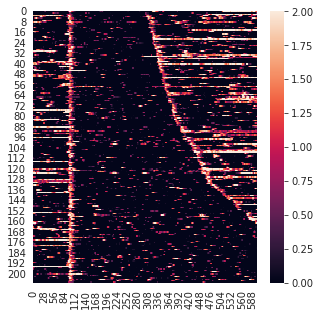

In [15]:
plt.figure(figsize=(5,5))
sns.heatmap(M_face_pc[:,:].transpose(),vmin=-0,vmax=2)

In [16]:
t_stop_resting = (M_ind_stop - M_ind)/4 +100

In [17]:
fake_M_face_pc = M_face_pc.copy()
fake_M_face_pc[:120,:]=np.nan
for i_stop,stop in enumerate(t_stop_resting):
    fake_M_face_pc[int(t_stop_resting[i_stop]):,i_stop]=np.nan

<AxesSubplot:>

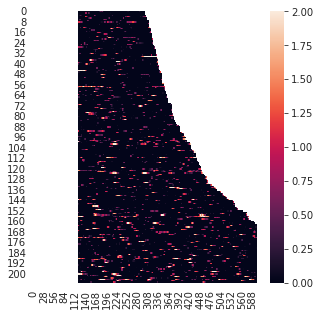

In [18]:
plt.figure(figsize=(5,5))
sns.heatmap(fake_M_face_pc[:,:].transpose(),vmin=-0,vmax=2)

In [19]:
T_PRE_new=130

(193,)


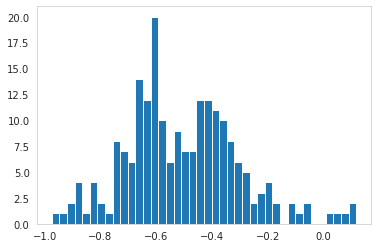

In [20]:
before_running_std = np.nanmean(fake_M_face_pc[:,:],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = -0.2
ss_ind = before_running_std<ss
print(np.where(ss_ind==True)[0].shape)


In [21]:
fake_M_face_pc = fake_M_face_pc[:,ss_ind]

M_jrgeco = M_jrgeco[:,:,ss_ind]
M_gcamp = M_gcamp[:,:,ss_ind]
M_chbt = M_chbt[:,:,ss_ind]
M_day_label = M_day_label[ss_ind]
M_ind = M_ind[ss_ind]
M_ind_stop = M_ind_stop[ss_ind]
M_LFP_vel=M_LFP_vel[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_body_pc=M_body_pc[:,ss_ind]
M_face_pc=M_face_pc[:,ss_ind]
M_body_pc_smooth= M_body_pc_smooth[:,ss_ind]
M_rotf=M_rotf[:,ss_ind]
M_rotf_smooth=M_rotf_smooth[:,ss_ind]
M_is_groom=M_is_groom[:,ss_ind]


M_mirrorRFP_vel = M_mirrorRFP_vel[:,ss_ind]
M_mirrorRFP_vel_norm = M_mirrorRFP_vel_norm[:,ss_ind]
M_mirrorLFP_vel = M_mirrorLFP_vel[:,ss_ind]
M_mirrorLFP_vel_norm = M_mirrorLFP_vel_norm[:,ss_ind]
M_mirrorRHP_vel = M_mirrorRHP_vel[:,ss_ind]
M_mirrorRHP_vel_norm = M_mirrorRHP_vel_norm[:,ss_ind]
M_mirrorLHP_vel = M_mirrorLHP_vel[:,ss_ind]
M_mirrorLHP_vel_norm = M_mirrorLHP_vel_norm[:,ss_ind]

(102,)


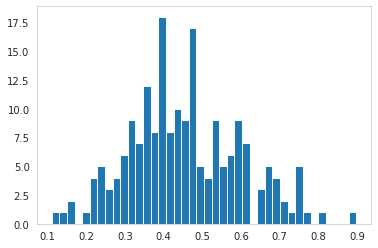

In [22]:
before_running_std = np.nanstd(fake_M_face_pc[:,:],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = 0.45
ss_ind = before_running_std<ss
print(np.where(ss_ind==True)[0].shape)


In [23]:
fake_M_face_pc = fake_M_face_pc[:,ss_ind]

M_jrgeco = M_jrgeco[:,:,ss_ind]
M_gcamp = M_gcamp[:,:,ss_ind]
M_chbt = M_chbt[:,:,ss_ind]
M_day_label = M_day_label[ss_ind]
M_ind = M_ind[ss_ind]
M_ind_stop = M_ind_stop[ss_ind]
M_LFP_vel=M_LFP_vel[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_body_pc=M_body_pc[:,ss_ind]
M_face_pc=M_face_pc[:,ss_ind]
M_body_pc_smooth= M_body_pc_smooth[:,ss_ind]
M_rotf=M_rotf[:,ss_ind]
M_rotf_smooth=M_rotf_smooth[:,ss_ind]
M_is_groom=M_is_groom[:,ss_ind]


M_mirrorRFP_vel = M_mirrorRFP_vel[:,ss_ind]
M_mirrorRFP_vel_norm = M_mirrorRFP_vel_norm[:,ss_ind]
M_mirrorLFP_vel = M_mirrorLFP_vel[:,ss_ind]
M_mirrorLFP_vel_norm = M_mirrorLFP_vel_norm[:,ss_ind]
M_mirrorRHP_vel = M_mirrorRHP_vel[:,ss_ind]
M_mirrorRHP_vel_norm = M_mirrorRHP_vel_norm[:,ss_ind]
M_mirrorLHP_vel = M_mirrorLHP_vel[:,ss_ind]
M_mirrorLHP_vel_norm = M_mirrorLHP_vel_norm[:,ss_ind]

In [50]:
# ss_ind = np.arange(70,M_jrgeco.shape[-1])

In [51]:
# fake_M_face_pc = fake_M_face_pc[:,ss_ind]

# M_jrgeco = M_jrgeco[:,:,ss_ind]
# M_gcamp = M_gcamp[:,:,ss_ind]
# M_chbt = M_chbt[:,:,ss_ind]
# M_day_label = M_day_label[ss_ind]
# M_ind = M_ind[ss_ind]
# M_ind_stop = M_ind_stop[ss_ind]
# M_LFP_vel=M_LFP_vel[:,ss_ind]
# M_RFP_vel=M_RFP_vel[:,ss_ind]
# M_body_pc=M_body_pc[:,ss_ind]
# M_face_pc=M_face_pc[:,ss_ind]
# M_body_pc_smooth= M_body_pc_smooth[:,ss_ind]
# M_rotf=M_rotf[:,ss_ind]
# M_rotf_smooth=M_rotf_smooth[:,ss_ind]
# M_is_groom=M_is_groom[:,ss_ind]


# M_mirrorRFP_vel = M_mirrorRFP_vel[:,ss_ind]
# M_mirrorRFP_vel_norm = M_mirrorRFP_vel_norm[:,ss_ind]
# M_mirrorLFP_vel = M_mirrorLFP_vel[:,ss_ind]
# M_mirrorLFP_vel_norm = M_mirrorLFP_vel_norm[:,ss_ind]
# M_mirrorRHP_vel = M_mirrorRHP_vel[:,ss_ind]
# M_mirrorRHP_vel_norm = M_mirrorRHP_vel_norm[:,ss_ind]
# M_mirrorLHP_vel = M_mirrorLHP_vel[:,ss_ind]
# M_mirrorLHP_vel_norm = M_mirrorLHP_vel_norm[:,ss_ind]

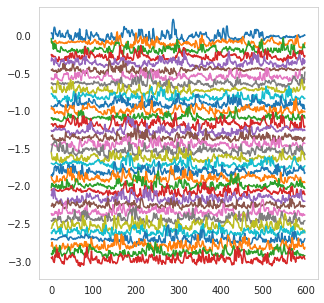

In [24]:
plt.figure(figsize=(5,5))
for i in range(0,M_jrgeco.shape[-1],3):
    plt.plot(M_jrgeco[sensory_ind['LM'],:,i]-0.03*i)

(0.0, 600.0)

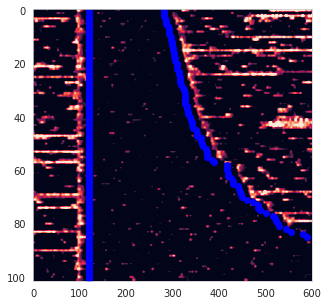

In [25]:
T_PRE_REST = 120
t_stop_resting = (M_ind_stop - M_ind)/4 +100-20
t_stop_resting=t_stop_resting.astype('int')

plt.figure(figsize=(5,5))
plt.imshow(M_face_pc[:,:].transpose(),vmin=-0,vmax=2,aspect='auto')
for i_stop,stop_ind in enumerate(t_stop_resting):
    plt.scatter(stop_ind,i_stop,color='blue')
    plt.scatter(T_PRE_REST,i_stop,color='blue')
plt.xlim([0,600])

In [27]:
ss_ind = np.arange(60,M_jrgeco.shape[-1])

In [28]:
fake_M_face_pc = fake_M_face_pc[:,ss_ind]

M_jrgeco = M_jrgeco[:,:,ss_ind]
M_gcamp = M_gcamp[:,:,ss_ind]
M_chbt = M_chbt[:,:,ss_ind]
M_day_label = M_day_label[ss_ind]
M_ind = M_ind[ss_ind]
M_ind_stop = M_ind_stop[ss_ind]
M_LFP_vel=M_LFP_vel[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_body_pc=M_body_pc[:,ss_ind]
M_face_pc=M_face_pc[:,ss_ind]
M_body_pc_smooth= M_body_pc_smooth[:,ss_ind]
M_rotf=M_rotf[:,ss_ind]
M_rotf_smooth=M_rotf_smooth[:,ss_ind]
M_is_groom=M_is_groom[:,ss_ind]


M_mirrorRFP_vel = M_mirrorRFP_vel[:,ss_ind]
M_mirrorRFP_vel_norm = M_mirrorRFP_vel_norm[:,ss_ind]
M_mirrorLFP_vel = M_mirrorLFP_vel[:,ss_ind]
M_mirrorLFP_vel_norm = M_mirrorLFP_vel_norm[:,ss_ind]
M_mirrorRHP_vel = M_mirrorRHP_vel[:,ss_ind]
M_mirrorRHP_vel_norm = M_mirrorRHP_vel_norm[:,ss_ind]
M_mirrorLHP_vel = M_mirrorLHP_vel[:,ss_ind]
M_mirrorLHP_vel_norm = M_mirrorLHP_vel_norm[:,ss_ind]

(0.0, 600.0)

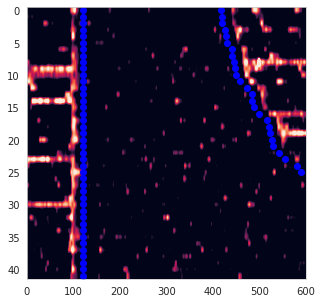

In [29]:
T_PRE_REST = 120
t_stop_resting = (M_ind_stop - M_ind)/4 +100-20
t_stop_resting=t_stop_resting.astype('int')

plt.figure(figsize=(5,5))
plt.imshow(M_face_pc[:,:].transpose(),vmin=-0,vmax=2,aspect='auto')
for i_stop,stop_ind in enumerate(t_stop_resting):
    plt.scatter(stop_ind,i_stop,color='blue')
    plt.scatter(T_PRE_REST,i_stop,color='blue')
plt.xlim([0,600])

In [30]:
M_jrgeco_REST = M_jrgeco
M_gcamp_REST = M_gcamp

M_day_label_REST = M_day_label
M_ind_REST=M_ind


# get full data

In [31]:
T_PRE_REST=100;
T_POST_REST=500;

In [32]:
state_types = ['REST']
for i_state, state in enumerate(state_types):
    exec("MM_jrgeco_{} = np.empty((256,256,M_jrgeco_{}.shape[1],0))".format(state,state))
    exec("M_jrgeco_here = M_jrgeco_{}".format(state))
    exec("M_day_label_here = M_day_label_{}".format(state))
    exec("M_ind_here = M_ind_{}".format(state))
    exec("T_PRE_here = T_PRE_{}".format(state))
    exec("T_POST_here = T_POST_{}".format(state))
    for i_bout in range(M_jrgeco_here.shape[-1]): 
        session_id = M_day_label_here[i_bout]
        day = session_id.split(mouse+'_')[1].split('_')[0]
        run_id = session_id.split(mouse+'_')[1].split('_')[1][:4]

        f3 = list(set(glob.glob(step_1_root+mouse+"/"+day+"/"+run_id+"*.mat")))[0]
        ind = int(M_ind_here[i_bout]/4) # CM229 !!!!!!

        with h5py.File(f3,'r') as f_H: 
            m = f_H['m']
            C = np.array(f_H['C']['jrgeco'])
            S = np.array(f_H['S']['jrgeco'])[ind-T_PRE_here:ind+T_POST_here,:]
            # cut [-60,60] frames slice
            # mask = np.array(f_H['mask'])
            # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
            nanidx = np.squeeze(m['nanidx'])==1
            CS = np.dot(S,C).transpose()
            jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
            jrgeco[:] = np.nan
            jrgeco[nanidx==True,:] = CS
            jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))

        exec("MM_jrgeco_{} = np.append(MM_jrgeco_{},jrgeco[:,:,:,np.newaxis],axis=3)".format(state,state))



In [33]:
save_filename = fetch_path_rest+'final_'+mouse+'_MM_jrgeco_'+mouse
hf = h5py.File(save_filename, 'w')
hf.create_dataset('MM_jrgeco_REST', data=MM_jrgeco_REST)
# hf.create_dataset('MM_jrgeco_RUN', data=MM_jrgeco_RUN)
hf.close()



In [57]:
load_filename = fetch_path_rest+'final_'+mouse+'_MM_jrgeco_'+mouse
hf = h5py.File(load_filename, 'r')
MM_jrgeco_REST = np.array(hf.get('MM_jrgeco_REST'))
hf.close()


In [35]:
behavior_dict = {'wheel_speed':M_rotf,'face_pc':M_face_pc,'LFP_speed':M_LFP_vel,
                'RFP_speed':M_RFP_vel,'M_ind':M_ind,'M_ind_stop':M_ind_stop,
                'M_day_label':M_day_label,'oromanual':M_is_groom,
                 'licking':np.zeros_like(M_rotf)}
save_pickle(behavior_dict,fetch_path_rest+'final_behavior_dict_'+mouse)

In [76]:
# ss=MM_jrgeco_REST.shape
# H_n_REST_full = MM_jrgeco_REST.reshape((ss[0]*ss[1],ss[2],ss[3]));


# ncomps = H_n_REST_full.shape[0];